# Image Captioning

This notebook is based directly on the Image Captioning with Visual Attention tutorial from the Tensorflow website. I have added some extra notes beyond the excellent notes that were already there. Generally there is just a lot of extra comments on notes to explain how things work. I have changed the text in some parts just to edit pronouns etc. 

Copyright 2018 The TensorFlow Authors with a couple of small additions by Robert Ross. 


Let's get going with some basic imports. 

In [1]:
import tensorflow as tf
from tensorflow import keras
from google.colab import drive

# You'll generate plots of attention in order to see which parts of an image
# our model focuses on during captioning
import matplotlib.pyplot as plt

# Scikit-learn includes many helpful utilities
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle

import collections
import random
import re
import numpy as np
import os
import time
import sys
import json
from glob import glob
from PIL import Image
import pickle
import shutil

ModuleNotFoundError: No module named 'google.colab'

Load up the drive directory we will work from - we don't want to work only from the VM as the creation of data takes too long to do each time from scratch. 

Note that if you are running this file for the first time from within an image, you will have to give a token to authorise it to access your drive location. 

In [2]:
print("Python Version: ", sys.version)
print(tf.__version__)

# Get the working directory on the node image -- we might want to return to this later
image_wd = os.getcwd()

# Mount the drive and go to the TalkingData directory 
#drive.mount('/content/drive')
#os.chdir('/content/drive/My Drive/TalkingData-Data/')
#drive_wd = os.getcwd()

Python Version:  3.7.10 (default, Feb 20 2021, 21:17:23) 
[GCC 7.5.0]
2.4.1


## Global Parameters

In [3]:
# Set the max (top) number of words we should use in our vocabulary. 
top_k = 5000

# size of the main vector that provides interface between encoder and decoder 
embedding_dim = 256

# Training batch size. 
BATCH_SIZE = 64

# Buffer size is used in the implementation of shuffling 
BUFFER_SIZE = 1000

# number of units to be used in the LSTM layer 
units = 512  

# vocab size is the top number of words we said we wanted plus 1 for the UNK word 
vocab_size = top_k + 1

# 8x8 = 64 areas that we can pay attention to 
attention_features_shape = 64

# define the number of images that we will use for training. 
Z = 600

# Setting the number of training epochs 
EPOCHS = 50

## Download and prepare the MS-COCO dataset

You will use the [MS-COCO dataset](http://cocodataset.org/#home) to train the model. The dataset contains over 82,000 images, each of which has at least 5 different caption annotations. The code below downloads and extracts the dataset automatically.

**Caution: large download ahead**. You'll use the training set, which is a 13GB file.

In [4]:
def download_and_prep():
  print("Downloading and preparing the MS-COCO dataset. ")

  # Download caption annotation files

  # folder where we will download the annotations to. 
  annotation_folder = '/annotations/'

  # If the annotations folder does not already exist 
  if not os.path.exists(os.path.abspath('.') + annotation_folder):
    # download and automatically extraction the captionz.ip file 
    annotation_zip = tf.keras.utils.get_file('captions.zip',
                                            cache_subdir=os.path.abspath('.'),
                                            origin = 'http://images.cocodataset.org/annotations/annotations_trainval2014.zip',
                                            extract = True)
    # get the full filename for the captions file 
    annotation_file = os.path.dirname(annotation_zip)+'/annotations/captions_train2014.json'
    # remove the original zip file 
    os.remove(annotation_zip)
  else:
    annotation_file = os.path.abspath('.') + annotation_folder + "captions_train2014.json"
  
  print("Annotation file: ", annotation_file)

  # Download image files

  # Locations for the image folder 
  image_folder = '/train2014/'

  # If the image folder does not exist 
  if not os.path.exists(os.path.abspath('.') + image_folder):
    # Download and extract the image file -- its big! 
    image_zip = tf.keras.utils.get_file('train2014.zip',
                                        cache_subdir=os.path.abspath('.'),
                                        origin = 'http://images.cocodataset.org/zips/train2014.zip',
                                        extract = True)
    # Path to the image folder 
    PATH = os.path.dirname(image_zip) + image_folder
    # Remove the zip file but keep the unpacked data 
    os.remove(image_zip)
  else:
    PATH = os.path.abspath('.') + image_folder

  print("PATH to image folder: ", PATH)

  # Load up the annotations from disk 
  with open(annotation_file, 'r') as f:
      annotations = json.load(f)    

  # Group all captions together having the same image ID.

  # create a dict object to link image paths to captions  
  image_path_to_caption = collections.defaultdict(list)
  # iterate over each annotation 
  for val in annotations['annotations']:
    # using f string to create a string based around the original caption 
    caption = f"<start> {val['caption']} <end>"
    # get the path to the relevent ms coco image
    image_path = PATH + 'COCO_train2014_' + '%012d.jpg' % (val['image_id'])
    # add the image path to the caption in the dict index. 
    image_path_to_caption[image_path].append(caption)      

  # extract all the image paths and shuffle them again 
  image_paths = list(image_path_to_caption.keys())
  random.shuffle(image_paths)

  # Select the first Z image_paths from the shuffled set.
  # Approximately each image id has 5 captions associated with it, so that will 
  # lead to 30,000 examples.
  train_image_paths = image_paths[:Z]    

  # create a list to store the training image captions 
  train_captions = []
  # create a list to store the image names 
  img_name_vector = []

  # for each image path 
  for image_path in train_image_paths:
    # get the five captions associated with the image
    caption_list = image_path_to_caption[image_path]
    # add these to the total list of training captions 
    train_captions.extend(caption_list)
    # add duplicates of the image path to the image name vector 
    img_name_vector.extend([image_path] * len(caption_list))

  return img_name_vector, train_captions, PATH

## Preprocess the images using InceptionV3
Next, you will use InceptionV3 (which is pretrained on Imagenet) to classify each image. You will extract features from the last convolutional layer. We are doing this in advance to speed up processing later. 

First, you will convert the images into InceptionV3's expected format by:
* Resizing the image to 299px by 299px
* [Preprocess the images](https://cloud.google.com/tpu/docs/inception-v3-advanced#preprocessing_stage) using the [preprocess_input](https://www.tensorflow.org/api_docs/python/tf/keras/applications/inception_v3/preprocess_input) method to normalize the image so that it contains pixels in the range of -1 to 1, which matches the format of the images used to train InceptionV3.

In [5]:
# Create the load_image function 
def load_image(image_path):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (299, 299))
    img = tf.keras.applications.inception_v3.preprocess_input(img)
    return img, image_path

## Initialize InceptionV3 and load the pretrained Imagenet weights

Now you'll create a tf.keras model where the output layer is the last convolutional layer in the InceptionV3 architecture. The shape of the output of this layer is ```8x8x2048```. You use the last convolutional layer because you are using attention in this example. You don't perform this initialization during training because it could become a bottleneck.

Let's start by defining our own new model based around the pre-trained InceptionV3 version. 


In [6]:
def create_cnn_model(): 
  print("Creating the CNN model.")
  # initialise the inception model based around the imagenet weights. We don't need the top. 
  image_model = tf.keras.applications.InceptionV3(include_top=False,
                                                  weights='imagenet')
  # make a reference to the input of that model. 
  new_input = image_model.input
  # make a reference to the output of that model. 
  hidden_layer = image_model.layers[-1].output

  # create a new model based around the original model. 
  image_features_extract_model = tf.keras.Model(new_input, hidden_layer)

  return image_features_extract_model

# We need to create this model for both training and testing, so therefore 
# we will just do it now, outside of the main functions. 
image_features_extract_model = create_cnn_model()  

Creating the CNN model.
87916544/87910968 [==============================] - 1s 0us/step


## Caching the features extracted from InceptionV3

You will pre-process each image with InceptionV3 and cache the output to disk. Caching the output in RAM would be faster but also memory intensive, requiring 8 \* 8 \* 2048 floats per image. At the time of writing, this exceeds the memory limitations of Colab (currently 12GB of memory).

Performance could be improved with a more sophisticated caching strategy (for example, by sharding the images to reduce random access disk I/O), but that would require more code.

The caching will take about 10 minutes to run in Colab with a GPU. If you'd like to see a progress bar, you can: 

1. install [tqdm](https://github.com/tqdm/tqdm):

    `!pip install tqdm`

2. Import tqdm:

    `from tqdm import tqdm`

3. Change the following line:

    `for img, path in image_dataset:`

    to:

    `for img, path in tqdm(image_dataset):`

As a reminder: 
* You forward each image through the network and store the resulting vector in a dictionary (image_name --> feature_vector).
* After all the images are passed through the network, you pickle the dictionary and save it to disk.

In [7]:
def process_image_vectors(img_name_vector,image_features_extract_model): 
  print("Extracting image vectors and saving to disk.")

  # sort the training image names 
  encode_train = sorted(set(img_name_vector))

  # Feel free to change batch_size according to your system configuration

  # convert the list of training image names to a dataset object 
  image_dataset = tf.data.Dataset.from_tensor_slices(encode_train)

  # create a function map that will load images in batches 
  image_dataset = image_dataset.map(
    load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(16)

  batch_counter = 1 

  # load images on the fly (in baatches) and process them 
  for img, path in image_dataset:
    print("Batch " + str(batch_counter), end=", ")
    batch_counter+=1

    # apply our extractor model to build the image features -- applied batchwise 
    batch_features = image_features_extract_model(img)
    # reshape to callapse two of the dimensions 
    batch_features = tf.reshape(batch_features,
                                (batch_features.shape[0], -1, batch_features.shape[3]))

    # store every element in the batch to disk 
    for bf, p in zip(batch_features, path):
      path_of_feature = p.numpy().decode("utf-8")
      np.save(path_of_feature, bf.numpy())

## Preprocess and tokenize the captions

* First, you'll tokenize the captions (for example, by splitting on spaces). This gives us a  vocabulary of all of the unique words in the data (for example, "surfing", "football", and so on).
* Next, you'll limit the vocabulary size to the top 5,000 words (to save memory). You'll replace all other words with the token "UNK" (unknown).
* You then create word-to-index and index-to-word mappings.
* Finally, you pad all sequences to be the same length as the longest one.

In [8]:
# Find the maximum length of any caption in our dataset
def calc_max_length(tensor):
    return max(len(t) for t in tensor)

In [9]:
def process_text_vectors(train_captions):
  print("Processing text vectors. ")
  
  # Create the tokenizer 
  tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=top_k,
                                                    oov_token="<unk>",
                                                    filters='!"#$%&()*+.,-/:;=?@[\]^_`{|}~ ')
  # Apply the tokenizer to the inputs 
  tokenizer.fit_on_texts(train_captions)

  # set the padding word 
  tokenizer.word_index['<pad>'] = 0
  tokenizer.index_word[0] = '<pad>'

  # Apply the tokenizer to the inputs 
  train_seqs = tokenizer.texts_to_sequences(train_captions)
  print(train_seqs[0])

  # Pad each vector to the max_length of the captions
  # If you do not provide a max_length value, pad_sequences calculates it automatically
  cap_vector = tf.keras.preprocessing.sequence.pad_sequences(train_seqs, padding='post')
  print(cap_vector[0])

  # Calculates the max_length, which is used to store the attention weights
  max_length = calc_max_length(train_seqs)
  print("max_length is: ", max_length)  

  return cap_vector, max_length, tokenizer

## Split the data into training and testing

In [10]:
def build_datasets(img_name_vector,cap_vector): 
  """Returns lists of image names and captions for training and validation."""

  print("Building training and testing lists.")

  # create a new dict to map images to the caption vector (not the caption) 
  img_to_cap_vector = collections.defaultdict(list)

  # iterate over image names and captions 
  for img, cap in zip(img_name_vector, cap_vector):
    # add this paid to the dictionary 
    img_to_cap_vector[img].append(cap)

  # Create training and validation sets using an 80-20 split randomly.
  # get the image names 
  img_keys = list(img_to_cap_vector.keys())
  # shuffle them 
  random.shuffle(img_keys)

  # find the index number that splits the data 80/20 
  slice_index = int(len(img_keys)*0.8)
  # Get the training and validation data keys 
  img_name_train_keys, img_name_val_keys = img_keys[:slice_index], img_keys[slice_index:]

  # make lists for the image and caption training data 
  img_name_train = []
  cap_train = []

  # iterate over the image training keys and build the lists 
  for imgt in img_name_train_keys:
    capt_len = len(img_to_cap_vector[imgt])
    img_name_train.extend([imgt] * capt_len)
    cap_train.extend(img_to_cap_vector[imgt])

  # Do the same for validation 
  img_name_val = []
  cap_val = []
  for imgv in img_name_val_keys:
    capv_len = len(img_to_cap_vector[imgv])
    img_name_val.extend([imgv] * capv_len)
    cap_val.extend(img_to_cap_vector[imgv])

  return img_name_train, cap_train, img_name_val, cap_val

## Run dataset creation and save the indexes to file so that we can use them again later if we want. 


In [11]:
def write_to_file(img_name_train, cap_train, img_name_val, cap_val, tokenizer, max_length ): 
  print("Writing key lists to disk to use later.")
  with open('img_name_train.data', 'wb') as filehandle:
      # store the data as binary data stream
      pickle.dump(img_name_train, filehandle)

  with open('cap_train.data', 'wb') as filehandle:
      # store the data as binary data stream
      pickle.dump(cap_train, filehandle)

  with open('img_name_val.data', 'wb') as filehandle:
      # store the data as binary data stream
      pickle.dump(img_name_val, filehandle)

  with open('cap_val.data', 'wb') as filehandle:
      # store the data as binary data stream
      pickle.dump(cap_val, filehandle)              

  with open('tokenizer.data', 'wb') as filehandle:
      # store the data as binary data stream
      pickle.dump(tokenizer, filehandle)                        

  with open('max_length.data', 'wb') as filehandle:
      # store the data as binary data stream
      pickle.dump(max_length, filehandle)                 

def read_from_file(): 
  print("Writing key objects back from disk.")
  with open('img_name_train.data', 'rb') as filehandle:
    # read the data as binary data stream
    img_name_train = pickle.load(filehandle)

  with open('cap_train.data', 'rb') as filehandle:
    # read the data as binary data stream
    cap_train = pickle.load(filehandle)

  with open('img_name_val.data', 'rb') as filehandle:
    # read the data as binary data stream
    img_name_val = pickle.load(filehandle)

  with open('cap_val.data', 'rb') as filehandle:
    # read the data as binary data stream
    cap_val = pickle.load(filehandle)           

  with open('tokenizer.data', 'rb') as filehandle:
    # read the data as binary data stream
    tokenizer = pickle.load(filehandle)        

  with open('max_length.data', 'rb') as filehandle:
    # read the data as binary data stream
    max_length = pickle.load(filehandle)       

  return  img_name_train, cap_train, img_name_val, cap_val, tokenizer, max_length

def prepare(): 
  print("Constructing the dataset...")
  img_name_vector, train_captions, PATH = download_and_prep()
  npy_counter = len(glob(PATH + "*.npy"))
  print("Number of npy files before calling extractor: ", npy_counter)
  if npy_counter < Z: 
    print("We need to generate the npy files.")
    process_image_vectors(img_name_vector,image_features_extract_model)
  cap_vector, max_length, tokenizer = process_text_vectors(train_captions)
  img_name_train, cap_train, img_name_val, cap_val = build_datasets(img_name_vector,cap_vector)
  write_to_file(img_name_train, cap_train, img_name_val, cap_val, tokenizer, max_length)
  print("Dataset construction complete.")
  return

## Model

Fun fact: the decoder below is identical to the one in the example for [Neural Machine Translation with Attention](../sequences/nmt_with_attention.ipynb).

The model architecture is inspired by the [Show, Attend and Tell](https://arxiv.org/pdf/1502.03044.pdf) paper.

* In this example, you extract the features from the lower convolutional layer of InceptionV3 giving us a vector of shape (8, 8, 2048).
* You squash that to a shape of (64, 2048).
* This vector is then passed through the CNN Encoder (which consists of a single Fully connected layer).
* The RNN (here GRU) attends over the image to predict the next word.

First, create an instance of the Bahdanau Attention mechanism as a model subclass. We will use this in the decoder below. 

For a good explanation of the mecanism, please see this blog:
https://blog.floydhub.com/attention-mechanism/

In [12]:
class BahdanauAttention(tf.keras.Model):

  # create the constructor - we need the number of units. 
  def __init__(self, units):
    """Parameterised with the number of units to be used in the LSTM layer. """
    super(BahdanauAttention, self).__init__()
    # used to weight the encoder states
    self.W1 = tf.keras.layers.Dense(units)
    # used to weight the decoder hidden state 
    self.W2 = tf.keras.layers.Dense(units)
    # the alignment score 
    self.V = tf.keras.layers.Dense(1)

  def call(self, features, hidden):
    """Takes features - the encoder outputs. 
             hidden -  the vector of hidden states produced by the decoder """

    # features(CNN_encoder output) shape == (batch_size, 64, embedding_dim)

    # hidden shape == (batch_size, hidden_size)
    # hidden_with_time_axis shape == (batch_size, 1, hidden_size)
    hidden_with_time_axis = tf.expand_dims(hidden, 1)

    # attention_hidden_layer shape == (batch_size, 64, units)
    attention_hidden_layer = (tf.nn.tanh(self.W1(features) +
                                         self.W2(hidden_with_time_axis)))

    # calculate the alignment score 
    # score shape == (batch_size, 64, 1)
    # This gives you an unnormalized score for each image feature.
    score = self.V(attention_hidden_layer)

    # attention_weights shape == (batch_size, 64, 1)
    attention_weights = tf.nn.softmax(score, axis=1)

    # context_vector shape after sum == (batch_size, hidden_size)
    context_vector = attention_weights * features
    context_vector = tf.reduce_sum(context_vector, axis=1)

    return context_vector, attention_weights

Now define the encoder. This isn't doing much as we are using an offline CNN to generate the features. 

In [13]:
class CNN_Encoder(tf.keras.Model):
    # Since you have already extracted the features and dumped it using pickle
    # This encoder passes those features through a Fully connected layer
    def __init__(self, embedding_dim):
        """Configure a single dense layer with the embedding size."""
        super(CNN_Encoder, self).__init__()
        # shape after fc == (batch_size, 64, embedding_dim)
        self.fc = tf.keras.layers.Dense(embedding_dim)

    def call(self, x):
        """the input embedding will be passed through a single dense layer with
        equal size and a relu activation function."""
        x = self.fc(x)
        x = tf.nn.relu(x)
        return x

Now the decoder, this is more involved as it has the LSTM decoder itself plus the implementation of attention. 

In [14]:
class RNN_Decoder(tf.keras.Model):
  def __init__(self, embedding_dim, units, vocab_size):
    super(RNN_Decoder, self).__init__()
    # The number of units to be used in the LSTM layer. 
    self.units = units

    # Set up the embedding layer - parameterised with vocab size 
    self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim)
    # Set up the RNN to have a particular number of units. We want to see the 
    # full unrolled hidden state. 
    self.gru = tf.keras.layers.GRU(self.units,
                                   return_sequences=True,
                                   return_state=True,
                                   recurrent_initializer='glorot_uniform')
    # We have a dense layer after the LSTM outputs. 
    self.fc1 = tf.keras.layers.Dense(self.units)
    # One more dense layer, but this time restrict to vocab size (our true output)
    self.fc2 = tf.keras.layers.Dense(vocab_size)

    # Instantiate the attention layer with the number of units used in the RNN
    self.attention = BahdanauAttention(self.units)

  def call(self, x, features, hidden):
    # defining attention as a separate model
    context_vector, attention_weights = self.attention(features, hidden)

    # Pass the input text through the embedding. Keep in mind that the input 
    # text is normally the start symbol or else the output of the RNN layer, 
    # i.e., the last word predicted. 
    # During training the word might be coming directly from the training data 
    # if teacher forcing is being used. 
    # x shape after passing through embedding == (batch_size, 1, embedding_dim)
    x = self.embedding(x)

    # concatenate the context vector with the processed inputs 
    # x shape after concatenation == (batch_size, 1, embedding_dim + hidden_size)
    x = tf.concat([tf.expand_dims(context_vector, 1), x], axis=-1)

    # passing the concatenated vector through the GRU
    output, state = self.gru(x)

    # Take the output and pass it through a dense layer 
    # shape == (batch_size, max_length, hidden_size)
    x = self.fc1(output)

    # flatten out batch_length 
    # x shape == (batch_size * max_length, hidden_size)
    x = tf.reshape(x, (-1, x.shape[2]))

    # Now pass through the final dense layer to produce words -- or rather one 
    # hot encodings of words. 
    # output shape == (batch_size * max_length, vocab)
    x = self.fc2(x)

    # return the word produced, the updated state vector from the GRU and 
    # the attention weights 
    return x, state, attention_weights

  def reset_state(self, batch_size):
    """Used to reset the weights at the end of a run.""" 
    return tf.zeros((batch_size, self.units))

Now that we have defined the encoder and decoder models, we can now instantiate them. 

In [15]:
def model_construction(): 
  print("Building the encoder-decoder model.")
  # parameterise the encoder with the size of output encodings 
  encoder = CNN_Encoder(embedding_dim)
  # parameterise the decoder with the expected size of inputs, number of units in 
  # the GRU and the dimensionality of the true output layer. 
  decoder = RNN_Decoder(embedding_dim, units, vocab_size)

  # We will use Adam as optimiser. 
  optimizer = tf.keras.optimizers.Adam()
  # Our basic loss is just cross entropy. We have to set it up to process from 
  # logits rather than a final softmax layer. We also ask it to calculate values 
  # for each input element. 
  loss_object = tf.keras.losses.SparseCategoricalCrossentropy(
      from_logits=True, reduction='none')
  
  return encoder, decoder, optimizer, loss_object

Now, let's set up training. This is a little bit more complex than we are used to dealing with. This is primarily due to the fact we are dealing with an LSTM output. 

In [16]:
# Now we need to define a loss function that will apply the loss object to our
# predictions and true values. 
def loss_function(real, pred, loss_object):
  # We don't want to care about padding words. 
  mask = tf.math.logical_not(tf.math.equal(real, 0))

  # calculate the actual loss 
  loss_ = loss_object(real, pred)

  # 
  mask = tf.cast(mask, dtype=loss_.dtype)

  # apply the mask over the loss 
  loss_ *= mask

  # Return the average loss over the unmasked sequence 
  return tf.reduce_mean(loss_)

## Checkpoint

Let's define a checkpoint callback object to save our models. We have seen how to do this in Keras. This is the pure tensorflow way of doing the same thing. Note that we can checkpoint multiple 'models' within our application. 

In [17]:
def setup_checkpoint(encoder, decoder, optimizer): 
  print("Setting up checkpoints.")
  
  checkpoint_path = "./checkpoints/train"
  # We up the checkpoint to monitor our encoder, decoder and optimizer. 
  # Note that there is nothing special about these three apat from the fact they 
  # are trainable. The argument names are arbitrary. 
  ckpt = tf.train.Checkpoint(encoder=encoder,
                            decoder=decoder,
                            optimizer = optimizer)
  # Configure the checkpoint manager. 
  ckpt_manager = tf.train.CheckpointManager(ckpt, checkpoint_path, max_to_keep=5)

  # If a checkpoint had already been saved, restore the network (encoder, decoder,
  # optimizer) based on that saved checkpoint file. 
  start_epoch = 0
  if ckpt_manager.latest_checkpoint:
    start_epoch = int(ckpt_manager.latest_checkpoint.split('-')[-1])
    # restoring the latest checkpoint in checkpoint_path
    ckpt.restore(ckpt_manager.latest_checkpoint)
  return start_epoch, ckpt_manager

## Training

Training is not aactually very complicated, but we do have to do a couple of steps manually. This makes it look more complex than it is. It is also worth noting again that we are not doing this in the Keras wrapper, so steps are a little bit more complex. 

* You extract the features stored in the respective `.npy` files and then pass those features through the encoder.
* The encoder output, hidden state(initialized to 0) and the decoder input (which is the start token) is passed to the decoder.
* The decoder returns the predictions and the decoder hidden state.
* The decoder hidden state is then passed back into the model and the predictions are used to calculate the loss.
* Use teacher forcing to decide the next input to the decoder.
* Teacher forcing is the technique where the target word is passed as the next input to the decoder.
* The final step is to calculate the gradients and apply it to the optimizer and backpropagate.


In [18]:
def copy_data(source_dir,dest_dir): 
  print("Copying content from drive to image.")
  print("Source dir: ", source_dir)
  print("Dest dir: ", dest_dir)
  print("Current dir: ", os.getcwd())
  print("Current dir contents: ", os.listdir())
  shutil.copytree(source_dir, dest_dir)

In [19]:
def build_dataset_objects(img_name_train, cap_train, img_name_val, cap_val): 
  """Takes lists of training and validation image names and captions, and 
      creates dataset objects. """ 

  print("Building dataset graph processing operations.")

  # Number of training steps required per epoch 
  num_steps = len(img_name_train) // BATCH_SIZE

  # Shape of the vector extracted from InceptionV3 after flattening is (64, 2048)
  # These two variables represent that vector shape
  # number of actual features / feature maps
  features_shape = 2048

  # function to load the numpy files
  def map_func(img_name, cap):
    img_tensor = np.load(img_name.decode('utf-8')+'.npy')
    return img_tensor, cap

  # build a new dataset object from the image training names and associated captions 
  dataset = tf.data.Dataset.from_tensor_slices((img_name_train, cap_train))

  # Setup the dataset map to load the numpy files in parallel - remember that it does not load them right now 
  dataset = dataset.map(lambda item1, item2: tf.numpy_function(
            map_func, [item1, item2], [tf.float32, tf.int32]),
            num_parallel_calls=tf.data.AUTOTUNE)

  # Set up shuffle and batch operations 
  dataset = dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE)
  dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)  

  return dataset, num_steps

In [20]:
@tf.function
def train_step(img_tensor, target, decoder, encoder, loss_object, optimizer, tokenizer):
  """Code up a single training step. """
  # Variable used to store the loss over multiple input tokens. 
  loss = 0

  # initializing the hidden state for each batch
  # because the captions are not related from image to image
  # This is just a lot of zeros. 
  hidden = decoder.reset_state(batch_size=target.shape[0])

  # Get the start token appropriately encoded. 
  dec_input = tf.expand_dims([tokenizer.word_index['<start>']] * target.shape[0], 1)

  # Set up a varaible to store the gradients over each set of input tokens. 
  with tf.GradientTape() as tape:
      # Get the features as produced by the encoder. 
      features = encoder(img_tensor)

      # For each word in the caption sequence (up to the buffered max lenght)
      for i in range(1, target.shape[1]):
          # pass the token, along with the image features through the decoder
          predictions, hidden, _ = decoder(dec_input, features, hidden)

          # Calculate the loss for this token position -- add to total step loss 
          loss += loss_function(target[:, i], predictions, loss_object)

          # using teacher forcing
          # take the next taken from the training data and set it up as input 
          # to the network. 
          dec_input = tf.expand_dims(target[:, i], 1)

  # Our step loss is the mean of the individual token losses 
  total_loss = (loss / int(target.shape[1]))

  # Get references to the trainable variables - we need to provide them for backprop 
  trainable_variables = encoder.trainable_variables + decoder.trainable_variables

  # Calculate gradient updates 
  gradients = tape.gradient(loss, trainable_variables)

  # Perform backprop
  optimizer.apply_gradients(zip(gradients, trainable_variables))

  return loss, total_loss

OK, now that our main training function has been defined we can set up the outer training proceedure. 

In [21]:
def run_training(dataset,encoder,decoder,loss_object, start_epoch, optimizer, num_steps, ckpt_manager, tokenizer): 
  print("Starting Training.")

  # List used to save the losses 
  loss_plot = []

  # for each epoch 
  for epoch in range(start_epoch, EPOCHS):
      # Let's save start time 
      start = time.time()
      # Reset the loss for this epoch 
      total_loss = 0

      # for each batch 
      for (batch, (img_tensor, target)) in enumerate(dataset):
          # apply the training step (weights will be updated)
          batch_loss, t_loss = train_step(img_tensor, target, decoder, encoder,loss_object, optimizer, tokenizer)
          # add the step loss to the epoch loss 
          total_loss += t_loss

          # for every 100 batches, let's print some debug information. 
          if batch % 100 == 0:
              print ('Epoch {} Batch {} Loss {:.4f}'.format(
                epoch + 1, batch, batch_loss.numpy() / int(target.shape[1])))
              
      # store the average epoch loss to plot later
      loss_plot.append(total_loss / num_steps)

      # save every fifth model. (only the last five will be kept)
      if epoch % 5 == 0:
        ckpt_manager.save()

      print ('Epoch {} Loss {:.6f}'.format(epoch + 1,
                                          total_loss/num_steps))
      print ('Time taken for 1 epoch {} sec\n'.format(time.time() - start))
    
  return loss_plot

def plot_losses(loss_plot):
  print("Plotting losses.")
  plt.plot(loss_plot)
  plt.xlabel('Epochs')
  plt.ylabel('Loss')
  plt.title('Loss Plot')
  plt.show()

def save_enc_dec(encoder,decoder):
  print("Saving the encoder/decoder to disk for later use.")
  encoder.save_weights('encoder')
  decoder.save_weights('decoder')

def train(): 
  #os.chdir(new_wd)
  #print("New Working directory: ", os.getcwd())
  img_name_train, cap_train, img_name_val, cap_val, tokenizer, max_length = read_from_file() 
  dataset, num_steps = build_dataset_objects(img_name_train, cap_train, img_name_val, cap_val)
  encoder, decoder, optimizer, loss_object = model_construction()
  start_epoch, ckpt_manager = setup_checkpoint(encoder, decoder, optimizer)
  loss_plot = run_training(dataset, encoder, decoder, loss_object, start_epoch, optimizer, num_steps, ckpt_manager, tokenizer)
  save_enc_dec(encoder,decoder)
  plot_losses(loss_plot)

  return

## Caption!

Now that training has been completed, we can generate some captions. 

* The evaluate function is similar to the training loop, except you don't use teacher forcing here. The input to the decoder at each time step is its previous predictions along with the hidden state and the encoder output.
* Stop predicting when the model predicts the end token.
* And store the attention weights for every time step.

In [22]:
def evaluate(image,encoder,decoder,max_length,tokenizer):
  """Generate a caption for the input image tensor."""
  
  print("Executing evaluation.")

  # create an array that we will use for visualisation purposes. 
  attention_plot = np.zeros((max_length, attention_features_shape))

  # Generate an initialisation hidden vector (all zeros)
  hidden = decoder.reset_state(batch_size=1)

  # shape the input image so that it can be provided to the encoder 
  temp_input = tf.expand_dims(load_image(image)[0], 0)
  img_tensor_val = image_features_extract_model(temp_input)
  img_tensor_val = tf.reshape(img_tensor_val, (img_tensor_val.shape[0], -1, img_tensor_val.shape[3]))

  # push the image through our encoder. 
  features = encoder(img_tensor_val)

  # get the start token to be supplied to the decoder 
  dec_input = tf.expand_dims([tokenizer.word_index['<start>']], 0)

  # create a list that we will use to store the produced words 
  result = []

  # We will generate up to the max length of strings that we established from 
  # the training data. 
  for i in range(max_length):
      # Given the current token (either init token or token from last iteration)
      # and my outputs from the decoder (these do not change within this generation loop)
      # and the decoder hidden state, use the lstm+attention layer to generate
      # outputs. 
      predictions, hidden, attention_weights = decoder(dec_input, features, hidden)

      # generate a plot of the attention weights for this token. 
      attention_plot[i] = tf.reshape(attention_weights, (-1, )).numpy()

      # Get the word and append it to the results 
      predicted_id = tf.random.categorical(predictions, 1)[0][0].numpy()
      result.append(tokenizer.index_word[predicted_id])

      # if we have hit the end token, return early. 
      if tokenizer.index_word[predicted_id] == '<end>':
          return result, attention_plot

      # prepare the output token to be fed back in as input to the decoder 
      dec_input = tf.expand_dims([predicted_id], 0)

  # update the complete attention plot and return it along with the result. 
  attention_plot = attention_plot[:len(result), :]
  return result, attention_plot

Just for the sake of visualisation, let's define a function that can overlap our attention model on the input image. 

In [23]:
def plot_attention(image, result, attention_plot):

  temp_image = np.array(Image.open(image))

  fig = plt.figure(figsize=(10, 10))

  len_result = len(result)
  for l in range(len_result):
      temp_att = np.resize(attention_plot[l], (8, 8))
      ax = fig.add_subplot(len_result//2, len_result//2, l+1)
      ax.set_title(result[l])
      img = ax.imshow(temp_image)
      ax.imshow(temp_att, cmap='gray', alpha=0.6, extent=img.get_extent())

  plt.tight_layout()
  plt.show()

In [24]:
def val_caption(encoder,decoder):
  img_name_train, cap_train, img_name_val, cap_val, tokenizer, max_length = read_from_file()
  # captions on the validation set
  rid = np.random.randint(0, len(img_name_val))
  image = img_name_val[rid]
  real_caption = ' '.join([tokenizer.index_word[i] for i in cap_val[rid] if i not in [0]])
  result, attention_plot = evaluate(image,encoder,decoder,max_length,tokenizer)

  print ('Real Caption:', real_caption)
  print ('Prediction Caption:', ' '.join(result))
  plot_attention(image, result, attention_plot)


## Try it on your own images
For fun, below we've provided a method you can use to caption your own images with the model we've just trained. Keep in mind, it was trained on a relatively small amount of data, and your images may be different from the training data (so be prepared for weird results!)


In [25]:
def run_test(encoder,decoder): 
  print("Individual Testing.")

  img_name_train, cap_train, img_name_val, cap_val, tokenizer, max_length = read_from_file()

  image_url = 'https://tensorflow.org/images/surf.jpg'
  image_extension = image_url[-4:]
  image_path = tf.keras.utils.get_file('image'+image_extension,
                                      origin=image_url)

  result, attention_plot = evaluate(image_path,encoder,decoder,max_length,tokenizer)
  print ('Prediction Caption:', ' '.join(result))
  plot_attention(image_path, result, attention_plot)
  # opening the image
  Image.open(image_path)

def load_enc_dec():
  # parameterise the encoder with the size of output encodings 
  encoder = CNN_Encoder(embedding_dim)
  # parameterise the decoder with the expected size of inputs, number of units in 
  # the GRU and the dimensionality of the true output layer. 
  decoder = RNN_Decoder(embedding_dim, units, vocab_size)

  encoder.load_weights('encoder')
  decoder.load_weights('decoder')
  return encoder, decoder 

def validate(): 
  encoder, decoder = load_enc_dec()
  print("Encoder and decoder loaded back.")
  val_caption(encoder,decoder)
  print("Val_caption finished")
  run_test(encoder,decoder)



Up to this point we have done little apart from defining our functions. Now it is time to run processing. 

Constructing the dataset...
252878848/252872794 [==============================] - 16s 0us/step
Annotation file:  /content/annotations/captions_train2014.json
13510574080/13510573713 [==============================] - 794s 0us/step
PATH to image folder:  /content/train2014/
Number of npy files before calling extractor:  0
We need to generate the npy files.
Extracting image vectors and saving to disk.
Batch 1, Batch 2, Batch 3, Batch 4, Batch 5, Batch 6, Batch 7, Batch 8, Batch 9, Batch 10, Batch 11, Batch 12, Batch 13, Batch 14, Batch 15, Batch 16, Batch 17, Batch 18, Batch 19, Batch 20, Batch 21, Batch 22, Batch 23, Batch 24, Batch 25, Batch 26, Batch 27, Batch 28, Batch 29, Batch 30, Batch 31, Batch 32, Batch 33, Batch 34, Batch 35, Batch 36, Batch 37, Batch 38, Processing text vectors. 
[3, 2, 41, 83, 19, 18, 14, 1015, 5, 2, 256, 4]
[   3    2   41   83   19   18   14 1015    5    2  256    4    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0

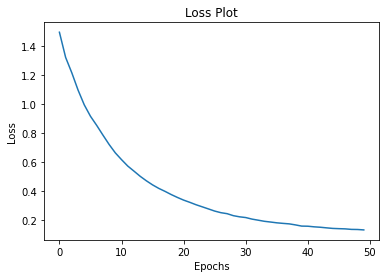

Encoder and decoder loaded back.
Writing key objects back from disk.
Executing evaluation.
Real Caption: <start> street signs at an intersection have flowers hanging above them <end>
Prediction Caption: the door st <end>


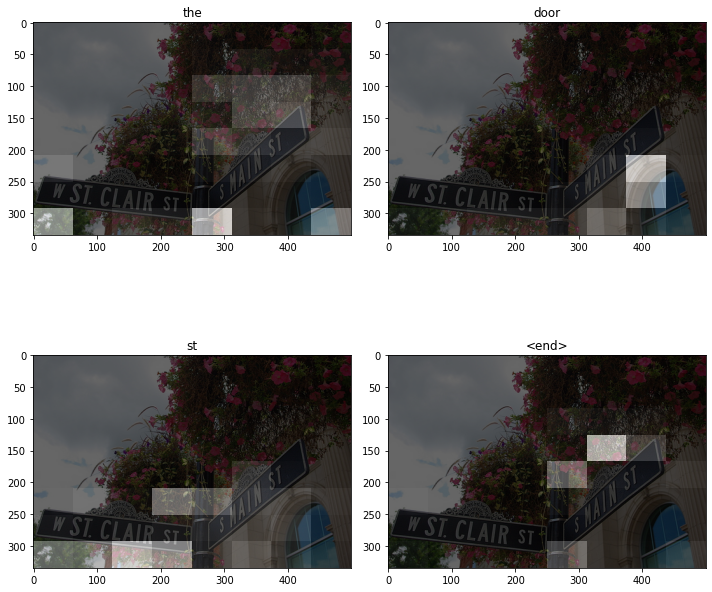

Val_caption finished
Individual Testing.
Writing key objects back from disk.
65536/64400 [==============================] - 0s 4us/step
Executing evaluation.
Prediction Caption: a wave on a surfboard on a surfboard on the water <end>


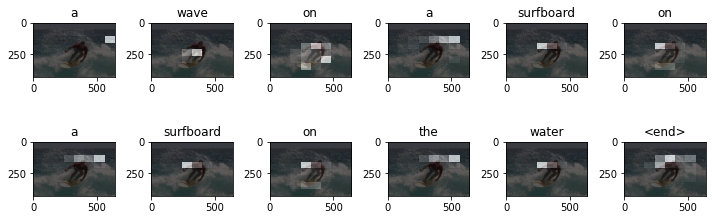

In [26]:
# Execute dataset preparation
prepare()

# Define the working directory for training 
# new_wd = image_wd + "/temp/"

# Copy dataset and all other necessary files from drive to image 
#copy_data(drive_wd,new_wd)

# Execute training
train()

# Execute validation
validate()

In [27]:
#@title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.